# CrossMed 03 - Evaluate saved models
Load saved checkpoints one at a time and evaluate each on BUS-BRA, BrEaST, and BUSI.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from crossmed.experiments import load_experiment_matrix, run_experiment_matrix, aggregate_results
PROJECT_ROOT = Path('..').resolve() if Path.cwd().name == 'notebooks' else Path.cwd().resolve()
MATRIX = PROJECT_ROOT / 'configs/experiment_matrix.yaml'
experiments = load_experiment_matrix(MATRIX)

## Select trained checkpoints

In [2]:
# SELECTED = ['resnet18_finetuned']
SELECTED = list(experiments)
CLEANUP_BETWEEN_MODELS = True

## Evaluate
Existing `evaluation.json` files are skipped. To recompute evaluation, change `skip_completed` to `False`.

In [7]:
comparison = run_experiment_matrix(
    MATRIX,
    selected=SELECTED,
    stage='evaluate',
    skip_completed=True,
    cleanup_between_runs=CLEANUP_BETWEEN_MODELS,
)
comparison


=== resnet18_finetuned ===
Skipping evaluation; results exist: /home/sidhu/Masters/CSCI566/CrossMed/outputs/baseline_resnet18/evaluation.json

=== resnet50_finetuned ===
Skipping evaluation; results exist: /home/sidhu/Masters/CSCI566/CrossMed/outputs/resnet50_finetuned_simple/evaluation.json

=== resnet101_finetuned ===
Skipping evaluation; results exist: /home/sidhu/Masters/CSCI566/CrossMed/outputs/resnet101_finetuned_simple/evaluation.json

=== resnet18_finetuned_mlp ===
Skipping evaluation; results exist: /home/sidhu/Masters/CSCI566/CrossMed/outputs/resnet18_finetuned_mlp/evaluation.json

=== resnet50_finetuned_mlp ===
Skipping evaluation; results exist: /home/sidhu/Masters/CSCI566/CrossMed/outputs/resnet50_finetuned_mlp/evaluation.json

=== resnet101_finetuned_mlp ===
Skipping evaluation; results exist: /home/sidhu/Masters/CSCI566/CrossMed/outputs/resnet101_finetuned_mlp/evaluation.json

=== resnet18_frozen_simple ===
                     n  accuracy balanced_accuracy        f1   

,experiment,dataset,n,accuracy,balanced_accuracy,precision,recall_sensitivity,specificity,f1,roc_auc
0,resnet18_finetuned,BUS-BRA_in_domain,375,0.816000,0.759655,0.784946,0.598361,0.920949,0.679070,0.868982
1,resnet18_finetuned,BrEaST_external,252,0.694444,0.716605,0.575540,0.816327,0.616883,0.675105,0.791810
2,resnet18_finetuned,BUSI_external,647,0.754250,0.771080,0.587031,0.819048,0.723112,0.683897,0.849226
3,resnet50_finetuned,BUS-BRA_in_domain,375,0.856000,0.842351,0.765625,0.803279,0.881423,0.784000,0.898772
4,resnet50_finetuned,BrEaST_external,252,0.714286,0.716141,0.612069,0.724490,0.707792,0.663551,0.794361
5,resnet50_finetuned,BUSI_external,647,0.754250,0.776027,0.584718,0.838095,0.713959,0.688845,0.874414
6,resnet101_finetuned,BUS-BRA_in_domain,375,0.826667,0.801513,0.735537,0.729508,0.873518,0.732510,0.915797
7,resnet101_finetuned,BrEaST_external,252,0.690476,0.704082,0.576923,0.765306,0.642857,0.657895,0.763451
8,resnet101_finetuned,BUSI_external,647,0.788253,0.797488,0.633700,0.823810,0.771167,0.716356,0.877177
9,resnet18_finetuned_mlp,BUS-BRA_in_domain,375,0.816000,0.787242,0.722689,0.704918,0.869565,0.713693,0.872870


## Reload all available results without loading a model

In [8]:
comparison = aggregate_results(MATRIX)
comparison

,experiment,dataset,n,accuracy,balanced_accuracy,precision,recall_sensitivity,specificity,f1,roc_auc
0,resnet18_finetuned,BUS-BRA_in_domain,375,0.816000,0.759655,0.784946,0.598361,0.920949,0.679070,0.868982
1,resnet18_finetuned,BrEaST_external,252,0.694444,0.716605,0.575540,0.816327,0.616883,0.675105,0.791810
2,resnet18_finetuned,BUSI_external,647,0.754250,0.771080,0.587031,0.819048,0.723112,0.683897,0.849226
3,resnet50_finetuned,BUS-BRA_in_domain,375,0.856000,0.842351,0.765625,0.803279,0.881423,0.784000,0.898772
4,resnet50_finetuned,BrEaST_external,252,0.714286,0.716141,0.612069,0.724490,0.707792,0.663551,0.794361
5,resnet50_finetuned,BUSI_external,647,0.754250,0.776027,0.584718,0.838095,0.713959,0.688845,0.874414
6,resnet101_finetuned,BUS-BRA_in_domain,375,0.826667,0.801513,0.735537,0.729508,0.873518,0.732510,0.915797
7,resnet101_finetuned,BrEaST_external,252,0.690476,0.704082,0.576923,0.765306,0.642857,0.657895,0.763451
8,resnet101_finetuned,BUSI_external,647,0.788253,0.797488,0.633700,0.823810,0.771167,0.716356,0.877177
9,resnet18_finetuned_mlp,BUS-BRA_in_domain,375,0.816000,0.787242,0.722689,0.704918,0.869565,0.713693,0.872870


## Cross-dataset ROC-AUC comparison

dataset,BUS-BRA_in_domain,BUSI_external,BrEaST_external
experiment,,,
resnet101_finetuned,0.915797,0.877177,0.763451
resnet101_finetuned_mlp,0.852103,0.859992,0.712762
resnet101_frozen_mlp,0.809888,0.823968,0.568447
resnet18_finetuned,0.868982,0.849226,0.791810
resnet18_finetuned_mlp,0.872870,0.881503,0.782998
resnet18_frozen_mlp,0.748979,0.826310,0.645640
resnet50_finetuned,0.898772,0.874414,0.794361
resnet50_finetuned_mlp,0.884695,0.883775,0.733866
resnet50_frozen_mlp,0.812901,0.832652,0.680957


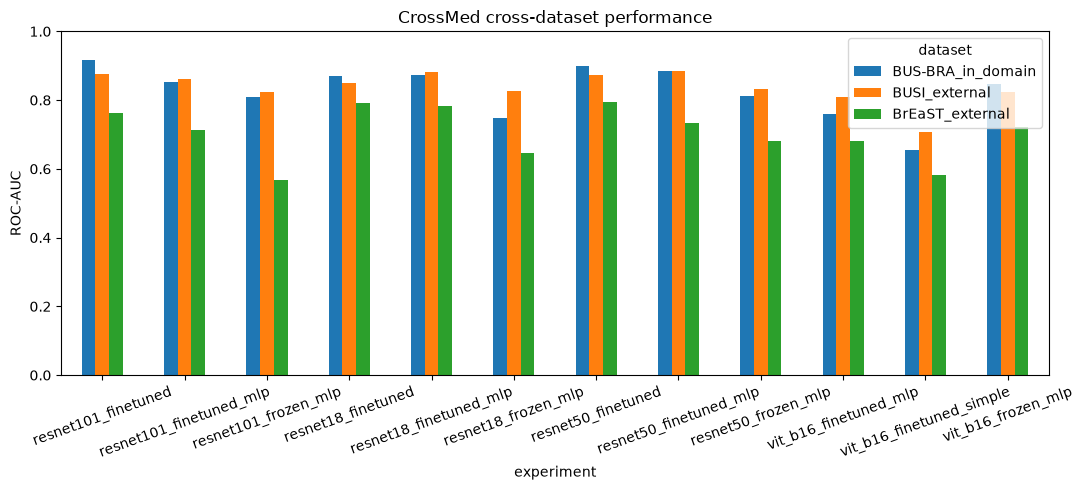

In [5]:
if not comparison.empty:
    auc_table = comparison.pivot(index='experiment', columns='dataset', values='roc_auc')
    display(auc_table)
    ax = auc_table.plot(kind='bar', figsize=(11, 5), ylim=(0, 1), rot=20)
    ax.set_ylabel('ROC-AUC')
    ax.set_title('CrossMed cross-dataset performance')
    plt.tight_layout()

## Other metrics

In [6]:
if not comparison.empty:
    display(comparison[['experiment', 'dataset', 'balanced_accuracy', 'recall_sensitivity', 'specificity', 'f1', 'roc_auc']])

,experiment,dataset,balanced_accuracy,recall_sensitivity,specificity,f1,roc_auc
0,resnet18_finetuned,BUS-BRA_in_domain,0.759655,0.598361,0.920949,0.679070,0.868982
1,resnet18_finetuned,BrEaST_external,0.716605,0.816327,0.616883,0.675105,0.791810
2,resnet18_finetuned,BUSI_external,0.771080,0.819048,0.723112,0.683897,0.849226
3,resnet50_finetuned,BUS-BRA_in_domain,0.842351,0.803279,0.881423,0.784000,0.898772
4,resnet50_finetuned,BrEaST_external,0.716141,0.724490,0.707792,0.663551,0.794361
5,resnet50_finetuned,BUSI_external,0.776027,0.838095,0.713959,0.688845,0.874414
6,resnet101_finetuned,BUS-BRA_in_domain,0.801513,0.729508,0.873518,0.732510,0.915797
7,resnet101_finetuned,BrEaST_external,0.704082,0.765306,0.642857,0.657895,0.763451
8,resnet101_finetuned,BUSI_external,0.797488,0.823810,0.771167,0.716356,0.877177
9,resnet18_finetuned_mlp,BUS-BRA_in_domain,0.787242,0.704918,0.869565,0.713693,0.872870
